# Kochi Air Quality Analysis – Exploratory Data Analysis (EDA)

## Introduction

Air pollution is one of the major environmental challenges affecting urban areas. It can have significant impacts on human health, the environment, and overall quality of life. Understanding air quality patterns is essential for identifying pollution trends and analyzing the factors contributing to air pollution.

This project focuses on exploring hourly air quality data from Kochi, Kerala, using Python. The dataset contains information about various air pollutants, including PM10, PM2.5, Nitrogen Dioxide (NO2), Sulphur Dioxide (SO2), Ozone (O3), Carbon Monoxide (CO), and the US Air Quality Index (AQI).

The objective of this project is to perform Exploratory Data Analysis (EDA) to understand pollution patterns, analyze pollutant concentrations, identify variations over time, and explore relationships between different air pollutants.

Through data cleaning, statistical analysis, and visualization, this project aims to discover meaningful insights from Kochi's air quality data and understand how air pollution levels vary across different time periods.

## Objectives

- Understand the structure and characteristics of the dataset.
- Identify missing values and duplicate records.
- Analyze the distribution of different air pollutants.
- Explore hourly and daily air quality patterns.
- Identify pollution peaks and variations over time.
- Compare air quality across weekdays, months, seasons and the two years of data.
- Check how often PM2.5 exceeds the WHO and CPCB limits.
- Analyze relationships between air pollutants and AQI.
- Generate meaningful insights through data visualization.

## Dataset Description

The dataset contains hourly air quality records for Kochi from **19 November 2024 to 19 November 2026**, a total of **17,544 rows** (one row per hour).

| Column | Description |
|---|---|
| datetime | Date and hour of the reading |
| pm10 | Particulate matter up to 10 micrometres (µg/m³) |
| pm2_5 | Particulate matter up to 2.5 micrometres (µg/m³) |
| nitrogen_dioxide | NO2 (µg/m³), mainly from traffic |
| sulphur_dioxide | SO2 (µg/m³) |
| ozone | O3 (µg/m³) |
| carbon_monoxide | CO (µg/m³) |
| us_aqi | US Air Quality Index |

**Source:** Open-Meteo Air Quality API (model-based estimates, not ground sensor readings).

**Limitations:** the dataset has no station or location column and no weather columns (rain, wind, temperature), so explanations such as the effect of the monsoon are likely reasons, not proven causes.

## Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Importing Libraries

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("All Libraries Imported Successfully")

All Libraries Imported Successfully


## Loading the Dataset

In [ ]:
df = pd.read_csv("../data/raw/kochi_air_quality_hourly.csv")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


## Displaying the First Five Rows

In [47]:
df.head()

,datetime,pm10,pm2_5,nitrogen_dioxide,sulphur_dioxide,ozone,carbon_monoxide,us_aqi
0,2024-11-19 00:00:00,30.3,30.0,20.9,5.9,36.0,646.0,97
1,2024-11-19 01:00:00,28.9,28.6,19.1,5.4,32.0,668.0,96
2,2024-11-19 02:00:00,27.1,26.9,17.9,5.1,28.0,676.0,95
3,2024-11-19 03:00:00,27.5,27.2,18.3,4.9,20.0,655.0,94
4,2024-11-19 04:00:00,27.4,27.2,19.3,4.8,13.0,619.0,92


**Summary:** The first record is 19 Nov 2024 at 00:00, with an AQI of 97. Each row is one hour and has seven measurement columns plus the datetime.

## Displaying the Last Five Rows

In [48]:
df.tail()

,datetime,pm10,pm2_5,nitrogen_dioxide,sulphur_dioxide,ozone,carbon_monoxide,us_aqi
17539,2026-11-19 19:00:00,42.6,40.7,32.9,9.7,79.0,304.0,146
17540,2026-11-19 20:00:00,50.3,48.7,41.5,10.8,51.0,337.0,127
17541,2026-11-19 21:00:00,54.1,52.9,43.9,10.9,37.0,438.0,100
17542,2026-11-19 22:00:00,55.8,54.7,42.8,10.3,31.0,573.0,98
17543,2026-11-19 23:00:00,54.6,53.8,40.4,9.7,28.0,673.0,98


**Summary:** The last record is 19 Nov 2026 at 23:00, so the data covers a full two years.

## Checking the Shape of the Dataset

In [49]:
df.shape

(17544, 8)

**Summary:** The dataset has 17,544 rows and 8 columns. 17,544 hourly records equal 731 days, which is about two years.

## Dataset Information

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   datetime          17544 non-null  str    
 1   pm10              17544 non-null  float64
 2   pm2_5             17544 non-null  float64
 3   nitrogen_dioxide  17544 non-null  float64
 4   sulphur_dioxide   17544 non-null  float64
 5   ozone             17544 non-null  float64
 6   carbon_monoxide   17544 non-null  float64
 7   us_aqi            17544 non-null  int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 1.4 MB


**Summary:** All seven measurement columns are numeric with no null values. The `datetime` column is stored as text (object), so it must be converted before any date operations.

## Statistical Summary of the Dataset

In [51]:
df.describe()

,pm10,pm2_5,nitrogen_dioxide,sulphur_dioxide,ozone,carbon_monoxide,us_aqi
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,29.081618,25.171227,14.021552,4.809718,66.924134,291.413874,84.034884
std,15.029078,15.539485,11.225189,2.484519,48.262221,155.388834,31.243156
min,3.500000,3.100000,0.900000,0.800000,0.000000,75.000000,33.000000
25%,17.000000,12.300000,5.000000,3.000000,30.000000,163.000000,57.000000
50%,26.100000,21.300000,11.300000,4.400000,53.000000,262.000000,76.000000
75%,38.500000,35.000000,19.800000,6.100000,93.000000,375.000000,103.000000
max,95.000000,93.800000,79.900000,17.000000,227.000000,1080.000000,201.000000


**Summary:** The average AQI is 84.0, ranging from 33 to 201. Average PM2.5 is 25.2 µg/m³ and average PM10 is 29.1 µg/m³. Carbon monoxide has the highest average (291.4 µg/m³) because it occurs in much larger amounts than the other pollutants, so it is plotted separately in Q3.

## Checking Missing Values

In [52]:
df.isnull().sum()

datetime            0
pm10                0
pm2_5               0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
carbon_monoxide     0
us_aqi              0
dtype: int64

**Summary:** No column has missing values, so no imputation or row removal is needed.

## Checking Duplicate Values

In [53]:
df.duplicated().sum()

np.int64(0)

**Summary:** There are 0 duplicate rows.

## Checking Unique Values

In [54]:
df.nunique()

datetime            17544
pm10                  629
pm2_5                 630
nitrogen_dioxide      591
sulphur_dioxide       160
ozone                 223
carbon_monoxide       795
us_aqi                162
dtype: int64

**Summary:** `datetime` has 17,544 unique values, one for every row, which confirms that no hour is repeated.

# Data Cleaning

### Checking Data Types

In [55]:
df.dtypes

datetime                str
pm10                float64
pm2_5               float64
nitrogen_dioxide    float64
sulphur_dioxide     float64
ozone               float64
carbon_monoxide     float64
us_aqi                int64
dtype: object

**Summary:** `datetime` is an object (text) column and needs to be converted to a proper date type. All other columns are already numeric.

### Converting the Datetime Column

In [56]:
df["datetime"] = pd.to_datetime(df["datetime"])

print(df["datetime"].min())
print(df["datetime"].max())

2024-11-19 00:00:00
2026-11-19 23:00:00


**Summary:** After conversion the data runs from 19 Nov 2024 to 19 Nov 2026.

### Checking for Missing Hours

In [57]:
gaps = df["datetime"].diff()

print("Missing hourly intervals:", (gaps > pd.Timedelta("1 hour")).sum())
print("Total rows:", len(df))

Missing hourly intervals: 0
Total rows: 17544


**Summary:** There are 0 missing hourly intervals, so the time series is complete with exactly one record per hour.

### Checking Suspicious Values

In [58]:
print("Zero values in each column:")
print((df.drop(columns="datetime") == 0).sum())

Zero values in each column:
pm10                 0
pm2_5                0
nitrogen_dioxide     0
sulphur_dioxide      0
ozone               35
carbon_monoxide      0
us_aqi               0
dtype: int64


**Summary:** Only the ozone column contains zeros (35 readings). They may be a model floor rather than true zero readings. They are only 0.2% of all rows, so they were kept.

### Creating New Columns (Feature Engineering)

New columns are created from the datetime column. `month` is stored as a month name, `season` follows the Indian climate pattern (Winter: Dec to Feb, Summer: Mar to May, Monsoon: Jun to Sep, Post-monsoon: Oct to Nov), and `period` splits the data into two equal 12-month blocks.

In [59]:
df["date"] = df["datetime"].dt.date
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month_name()
df["hour"] = df["datetime"].dt.hour
df["weekday"] = df["datetime"].dt.day_name()
df["is_weekend"] = df["datetime"].dt.dayofweek >= 5

df["season"] = df["datetime"].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
})


df["aqi_category"] = pd.cut(
    df["us_aqi"],
    bins=[-1, 50, 100, 150, 200, float("inf")],
    labels=["Good", "Moderate", "Unhealthy for Sensitive",
            "Unhealthy", "Very Unhealthy"]
)


df["period"] = np.where(df["datetime"] < "2025-11-19", "Year 1", "Year 2")


pollutants = ["pm10", "pm2_5", "nitrogen_dioxide",
               "sulphur_dioxide", "ozone", "carbon_monoxide"]


daily = df.groupby("date")[pollutants + ["us_aqi"]].mean()

df.head()

,datetime,pm10,pm2_5,nitrogen_dioxide,sulphur_dioxide,ozone,carbon_monoxide,us_aqi,date,year,month,hour,weekday,is_weekend,season,aqi_category,period
0,2024-11-19 00:00:00,30.3,30.0,20.9,5.9,36.0,646.0,97,2024-11-19,2024,November,0,Tuesday,False,Post-monsoon,Moderate,Year 1
1,2024-11-19 01:00:00,28.9,28.6,19.1,5.4,32.0,668.0,96,2024-11-19,2024,November,1,Tuesday,False,Post-monsoon,Moderate,Year 1
2,2024-11-19 02:00:00,27.1,26.9,17.9,5.1,28.0,676.0,95,2024-11-19,2024,November,2,Tuesday,False,Post-monsoon,Moderate,Year 1
3,2024-11-19 03:00:00,27.5,27.2,18.3,4.9,20.0,655.0,94,2024-11-19,2024,November,3,Tuesday,False,Post-monsoon,Moderate,Year 1
4,2024-11-19 04:00:00,27.4,27.2,19.3,4.8,13.0,619.0,92,2024-11-19,2024,November,4,Tuesday,False,Post-monsoon,Moderate,Year 1


**Summary:** New columns were created for date, year, month, hour, weekday, weekend flag, season, AQI category and period. Year 1 runs from 19 Nov 2024 to 18 Nov 2025 (8,760 hours) and Year 2 from 19 Nov 2025 to 19 Nov 2026 (8,784 hours), so the two years can be compared fairly.

### Defining Order Lists and the AQI Category Function

These lists keep chart categories in a logical order, and `get_category` is used later for the daily summary file. Everything is defined here once, before it is used.

In [60]:
import os
os.makedirs("../images/key_charts", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

month_order    = ["January", "February", "March", "April", "May", "June",
                  "July", "August", "September", "October", "November", "December"]
season_order   = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
day_order      = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
category_order = ["Good", "Moderate", "Unhealthy for Sensitive", "Unhealthy", "Very Unhealthy"]

def get_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Moderate"
    elif aqi <= 150:
        return "Unhealthy for Sensitive"
    elif aqi <= 200:
        return "Unhealthy"
    else:
        return "Very Unhealthy"

### Checking the Updated Dataset

In [61]:
print("Updated Dataset Shape:", df.shape)
df.info()

Updated Dataset Shape: (17544, 17)
<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   datetime          17544 non-null  datetime64[us]
 1   pm10              17544 non-null  float64       
 2   pm2_5             17544 non-null  float64       
 3   nitrogen_dioxide  17544 non-null  float64       
 4   sulphur_dioxide   17544 non-null  float64       
 5   ozone             17544 non-null  float64       
 6   carbon_monoxide   17544 non-null  float64       
 7   us_aqi            17544 non-null  int64         
 8   date              17544 non-null  object        
 9   year              17544 non-null  int32         
 10  month             17544 non-null  str           
 11  hour              17544 non-null  int32         
 12  weekday           17544 non-null  str           
 13  is_weekend        17544 non-null  bool          
 14

**Summary:** The dataset now has 17,544 rows and 17 columns (the original 8 plus 9 new ones), and it is ready for analysis.

# Exploratory Data Analysis (EDA)

The analysis is divided into five parts: overall picture, time patterns, trends and bad days, relationships between pollutants, and deeper insights.

## Part A: Overall Picture

### Q1. How is AQI distributed across all hours?

Average AQI: 84.0
Median AQI: 76.0
Maximum AQI: 201


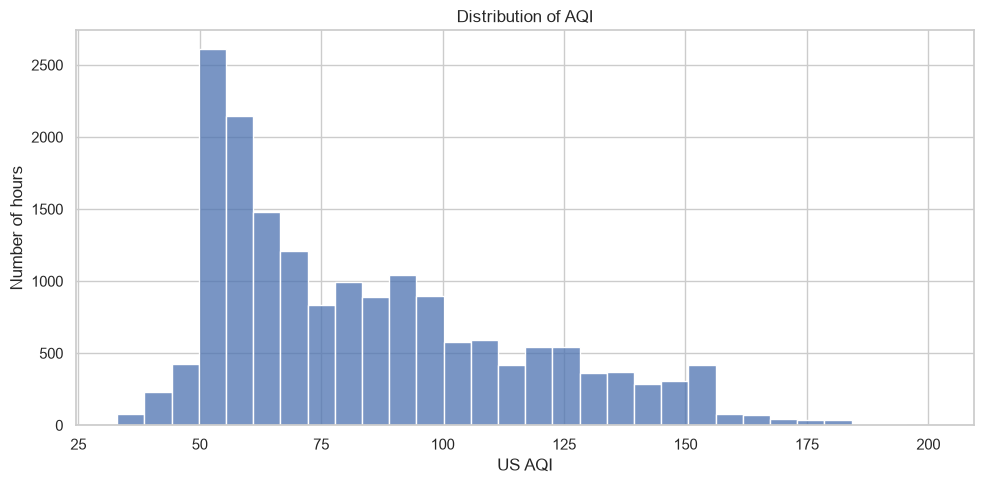

In [62]:
print("Average AQI:", round(df["us_aqi"].mean(), 1))
print("Median AQI:", df["us_aqi"].median())
print("Maximum AQI:", df["us_aqi"].max())

plt.figure(figsize=(10, 5))
sns.histplot(df["us_aqi"], bins=30)
plt.title("Distribution of AQI")
plt.xlabel("US AQI")
plt.ylabel("Number of hours")
plt.tight_layout()
plt.savefig("../images/key_charts/aqi_distribution.png")
plt.show()

**Summary:** The average AQI is 84.0 and the median is 76, with values from 33 to 201. Half of all hours fall between 57 and 103. About 26.8% of hours are above 100 and 4.0% are above 150, so the distribution has a long tail towards poor air quality, even though most hours are in the moderate range.

### Q2. What share of hours falls in each AQI category?

aqi_category
Good                        5.5
Moderate                   67.7
Unhealthy for Sensitive    22.8
Unhealthy                   4.0
Very Unhealthy              0.0
Name: proportion, dtype: float64


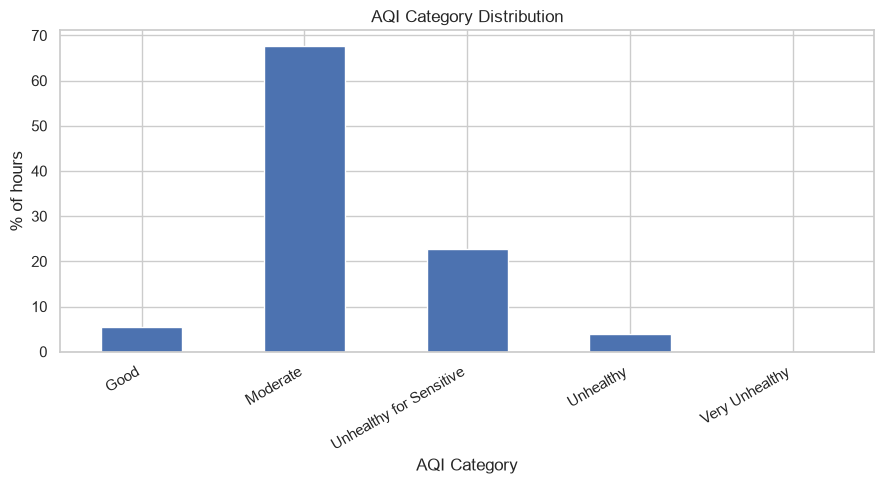

In [63]:
category_share = (df["aqi_category"].value_counts(normalize=True) * 100).reindex(category_order)
print(category_share.round(1))

plt.figure(figsize=(9, 5))
category_share.plot(kind="bar")
plt.title("AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("% of hours")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../images/key_charts/aqi_category_share.png")
plt.show()

**Summary:** Moderate is the most common category at 67.7% of hours, followed by Unhealthy for Sensitive Groups at 22.8%. Only 5.5% of hours are Good and 4.0% are Unhealthy, and no hour is Very Unhealthy. The air is rarely clean, but severe pollution is also rare.

### Q3. Which pollutants have the highest average levels?

pm10                 29.1
pm2_5                25.2
nitrogen_dioxide     14.0
sulphur_dioxide       4.8
ozone                66.9
carbon_monoxide     291.4
dtype: float64


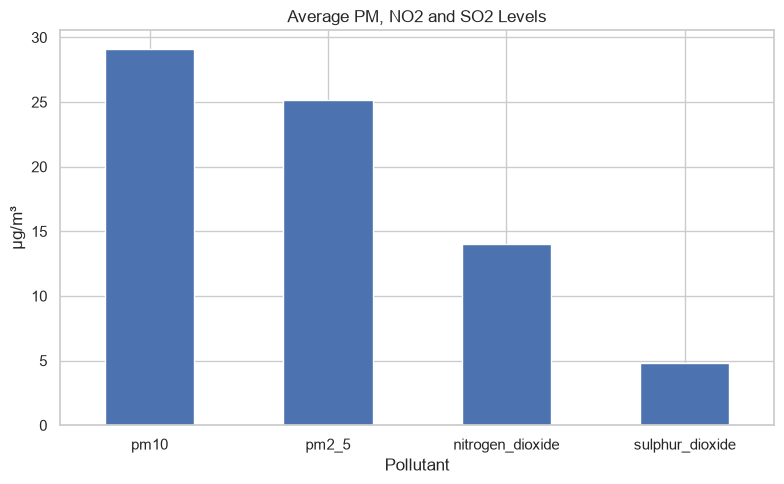

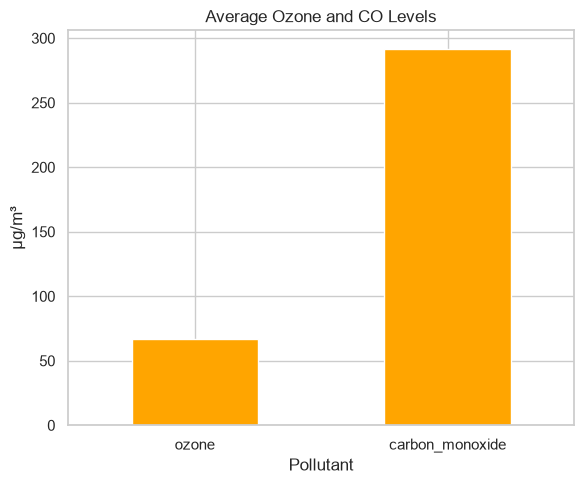

In [64]:
print(df[pollutants].mean().round(1))

plt.figure(figsize=(8, 5))
df[["pm10", "pm2_5", "nitrogen_dioxide", "sulphur_dioxide"]].mean().plot(kind="bar")
plt.title("Average PM, NO2 and SO2 Levels")
plt.xlabel("Pollutant")
plt.ylabel("µg/m³")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/key_charts/average_pollutants.png")
plt.show()

plt.figure(figsize=(6, 5))
df[["ozone", "carbon_monoxide"]].mean().plot(kind="bar", color="orange")
plt.title("Average Ozone and CO Levels")
plt.xlabel("Pollutant")
plt.ylabel("µg/m³")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/key_charts/average_ozone_co.png")
plt.show()

**Summary:** In the first chart PM10 (29.1 µg/m³) and PM2.5 (25.2) are the highest, followed by NO₂ (14.0) and SO₂ (4.8). In the second chart carbon monoxide averages 291.4 µg/m³ and ozone 66.9. CO is far higher because it occurs in much larger amounts, which is why the two are shown separately.

### Q4. How is PM2.5 distributed?

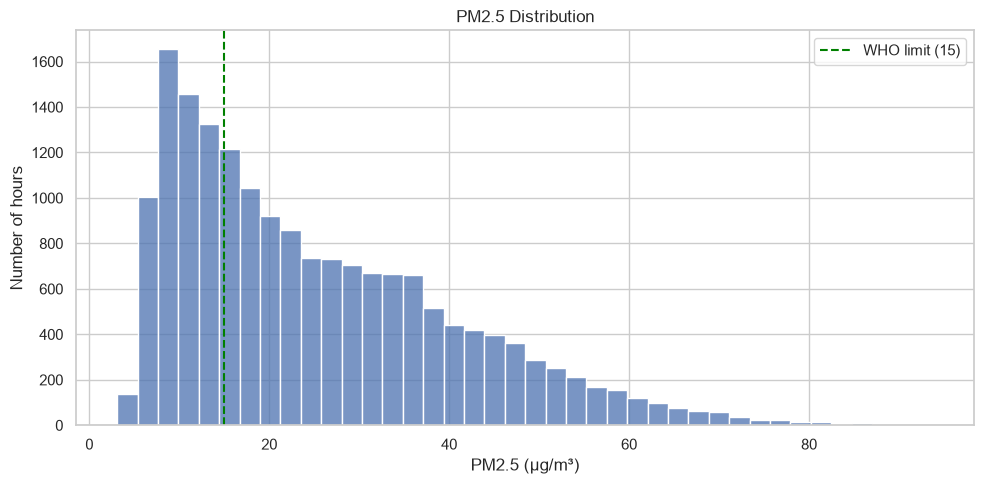

Hours above 15: 66.4 %


In [65]:
plt.figure(figsize=(10, 5))
sns.histplot(df["pm2_5"], bins=40)
plt.axvline(15, color="green", linestyle="--", label="WHO limit (15)")
plt.title("PM2.5 Distribution")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Number of hours")
plt.legend()
plt.tight_layout()
plt.savefig("../images/key_charts/pm2_5_distribution.png")
plt.show()

print("Hours above 15:", round((df["pm2_5"] > 15).mean() * 100, 1), "%")

**Summary:** PM2.5 averages 25.2 µg/m³ with a median of 21.3, and the distribution is right-skewed with a long tail up to 93.8. About 66.4% of hours are above the WHO guideline of 15 µg/m³. This is an hourly comparison (the WHO limit is for a 24-hour average), so Q18 checks it properly on daily averages.

### Q5. Are there outliers in PM2.5?

Median: 21.3
Q1 and Q3: 12.3 35.0
Upper outlier limit: 69.0
Outliers: 189


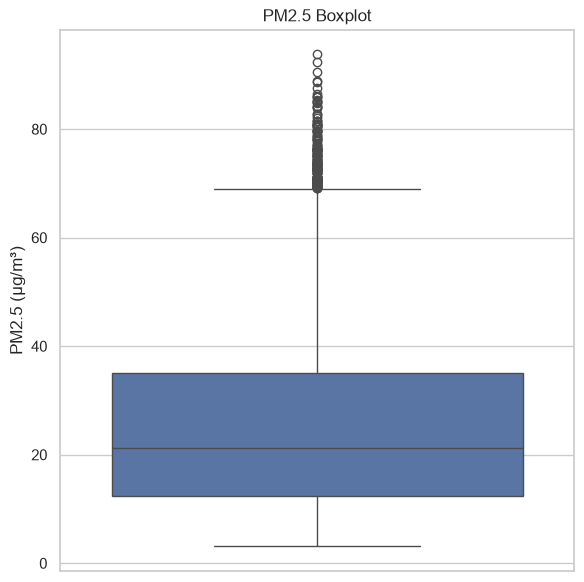

In [66]:
q1 = df["pm2_5"].quantile(0.25)
q3 = df["pm2_5"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

print("Median:", df["pm2_5"].median())
print("Q1 and Q3:", q1, q3)
print("Upper outlier limit:", round(upper_limit, 1))
print("Outliers:", (df["pm2_5"] > upper_limit).sum())

plt.figure(figsize=(6, 6))
sns.boxplot(y=df["pm2_5"])
plt.title("PM2.5 Boxplot")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig("../images/key_charts/pm2_5_boxplot.png")
plt.show()

**Summary:** The median PM2.5 is 21.3 µg/m³ and the middle half of readings lies between 12.3 and 35.0. There are 189 outliers above about 69.1 µg/m³, with a maximum of 93.8. All of them fall between October and March (none in the monsoon), so they look like genuine pollution episodes, not errors, and they were kept.

## Part B: Time Patterns

### Q6. Which hours of the day are most polluted?

Most polluted hour: 18 | AQI: 94.4
Cleanest hour: 12 | AQI: 81.5


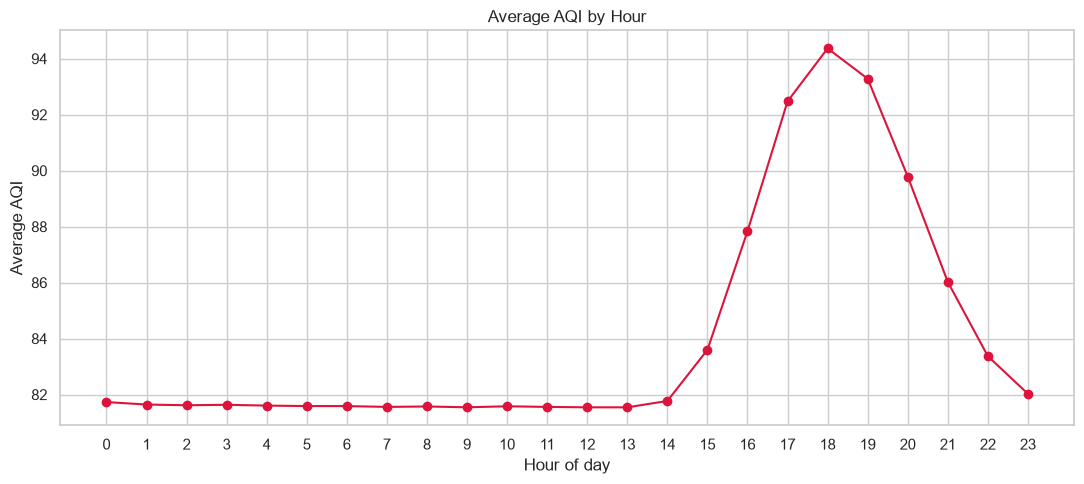

In [67]:
hourly_aqi = df.groupby("hour")["us_aqi"].mean()

print("Most polluted hour:", hourly_aqi.idxmax(), "| AQI:", round(hourly_aqi.max(), 1))
print("Cleanest hour:", hourly_aqi.idxmin(), "| AQI:", round(hourly_aqi.min(), 1))

plt.figure(figsize=(11, 5))
hourly_aqi.plot(kind="line", marker="o", color="crimson")
plt.title("Average AQI by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average AQI")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("../images/key_charts/hourly_aqi.png")
plt.show()

**Summary:** AQI stays almost flat at about 82 from midnight to mid-afternoon, then rises from 15:00 to a peak of 94.4 at 18:00 before falling again. The lowest value is at 12:00 (81.5), although the whole period from 00:00 to 14:00 is nearly identical. The evening is therefore the most polluted time of day.

### Q7. How does NO₂ change through the day?

NO2 peak hour: 22 | value: 26.8
NO2 lowest hour: 13 | value: 2.4


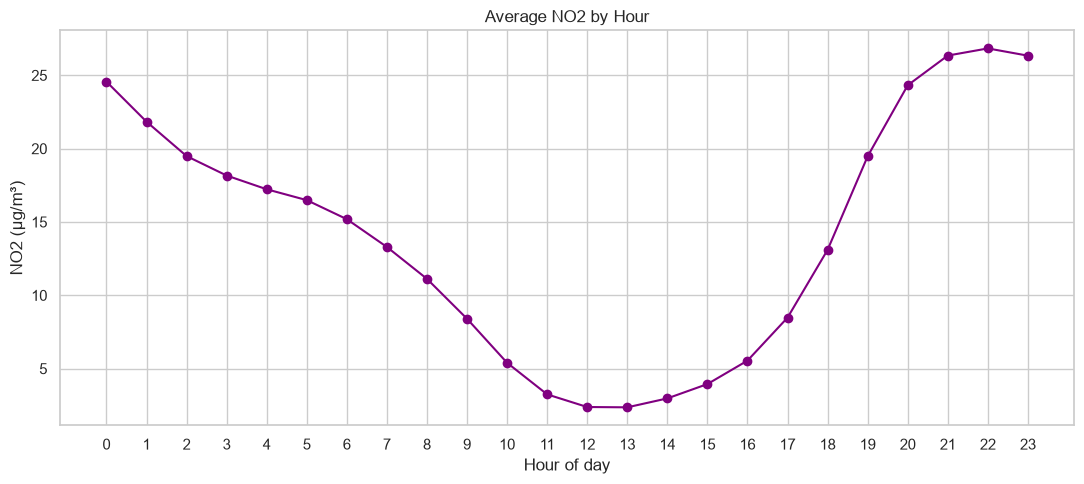

In [68]:
hourly_no2 = df.groupby("hour")["nitrogen_dioxide"].mean()

print("NO2 peak hour:", hourly_no2.idxmax(), "| value:", round(hourly_no2.max(), 1))
print("NO2 lowest hour:", hourly_no2.idxmin(), "| value:", round(hourly_no2.min(), 1))

plt.figure(figsize=(11, 5))
hourly_no2.plot(kind="line", marker="o", color="purple")
plt.title("Average NO2 by Hour")
plt.xlabel("Hour of day")
plt.ylabel("NO2 (µg/m³)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("../images/key_charts/hourly_no2.png")
plt.show()

**Summary:** NO₂ is highest at night, peaking at 22:00 (26.8 µg/m³), and lowest at 13:00 (2.4 µg/m³). It climbs steeply from about 17:00. The very low afternoon value is likely because sunlight and daytime mixing remove NO₂ from the air, while it builds up after sunset.

### Q8. How does ozone change through the day?

Ozone peak hour: 13 | value: 119.5
Ozone lowest hour: 4 | value: 25.7


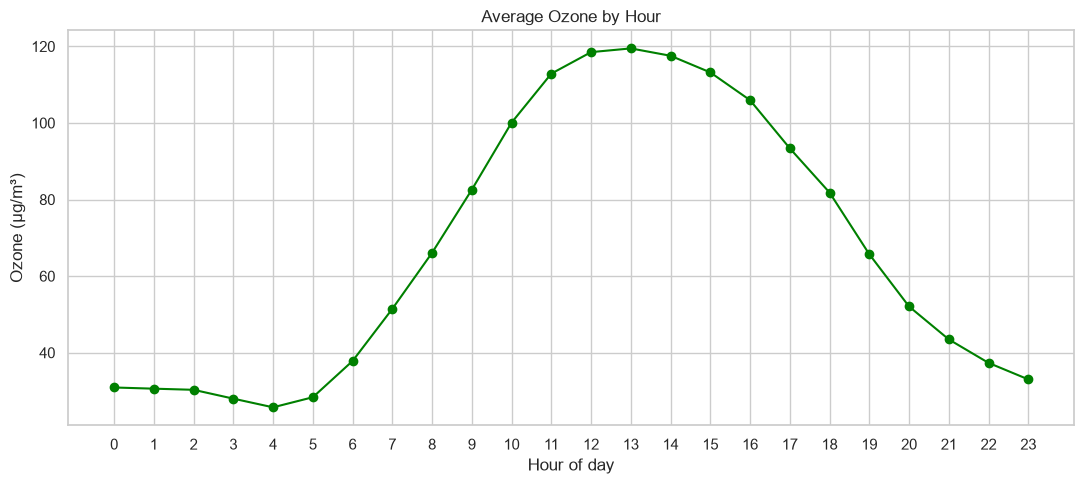

In [69]:
hourly_ozone = df.groupby("hour")["ozone"].mean()

print("Ozone peak hour:", hourly_ozone.idxmax(), "| value:", round(hourly_ozone.max(), 1))
print("Ozone lowest hour:", hourly_ozone.idxmin(), "| value:", round(hourly_ozone.min(), 1))

plt.figure(figsize=(11, 5))
hourly_ozone.plot(kind="line", marker="o", color="green")
plt.title("Average Ozone by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Ozone (µg/m³)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("../images/key_charts/hourly_ozone.png")
plt.show()

**Summary:** Ozone peaks at 13:00 (119.5 µg/m³), when sunlight is strongest, and is lowest at 04:00 (25.7 µg/m³). Ozone is formed by sunlight, so it rises in the day and falls at night. This is the mirror image of NO₂ in Q7.

### Q9. Which weekday has the worst air?

weekday
Monday       82.1
Tuesday      84.8
Wednesday    84.4
Thursday     84.7
Friday       85.0
Saturday     84.1
Sunday       83.2
Name: us_aqi, dtype: float64


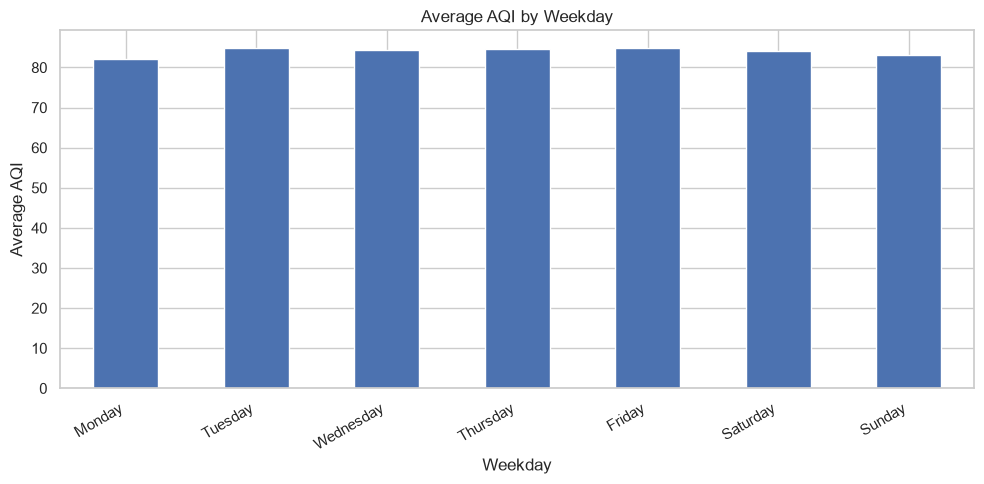

In [70]:
weekday_aqi = df.groupby("weekday")["us_aqi"].mean().reindex(day_order)

print(weekday_aqi.round(1))

plt.figure(figsize=(10, 5))
weekday_aqi.plot(kind="bar")
plt.title("Average AQI by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average AQI")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../images/key_charts/weekday_aqi.png")
plt.show()

**Summary:** Friday has the highest average AQI (85.0) and Monday the lowest (82.1), a gap of only 2.9 points. All seven days sit in a narrow band, so the day of the week has very little effect on air quality.

### Q10. Is the air better on weekends?

Weekday    84.2
Weekend    83.6
Name: us_aqi, dtype: float64


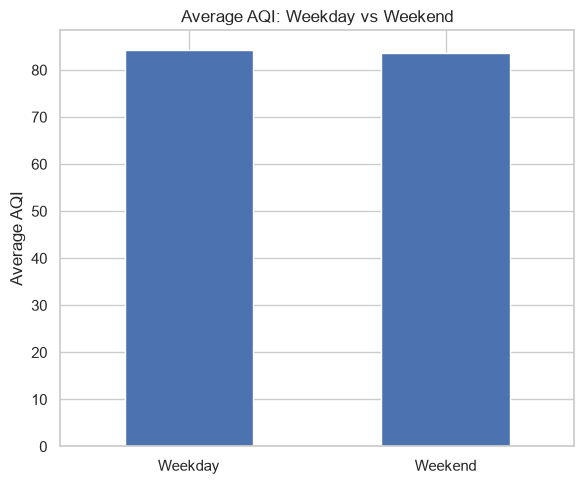

In [71]:
weekend_aqi = df.groupby("is_weekend")["us_aqi"].mean()
weekend_aqi.index = ["Weekday", "Weekend"]

print(weekend_aqi.round(1))

plt.figure(figsize=(6, 5))
weekend_aqi.plot(kind="bar")
plt.title("Average AQI: Weekday vs Weekend")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../images/key_charts/weekend_aqi.png")
plt.show()

**Summary:** Weekdays average 84.2 and weekends 83.6, a difference of just 0.6 points (about 0.7%). Air quality in Kochi does not change meaningfully between working days and weekends.

### Q11. Which months are worst and best?

Worst month: February | AQI: 120.6
Best month: August | AQI: 55.0


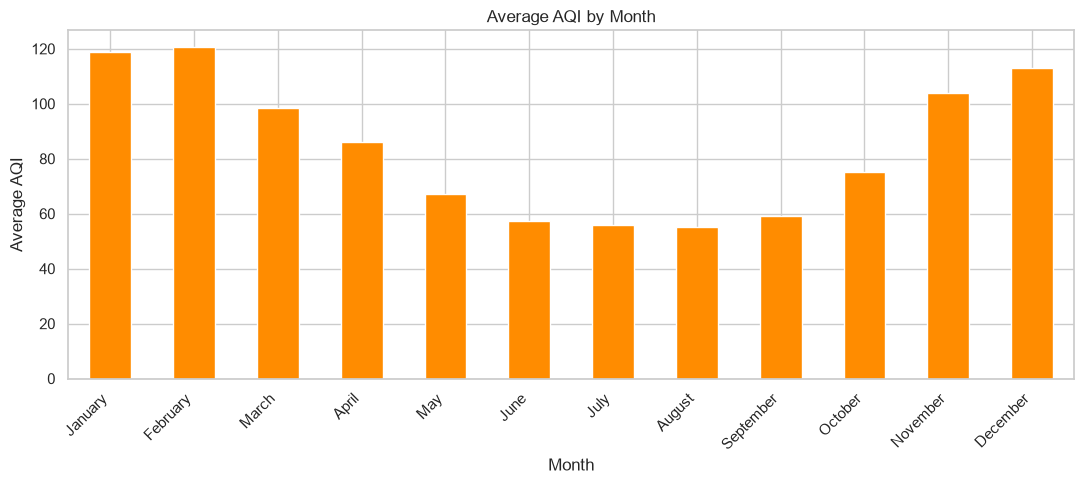

In [72]:
monthly_aqi = df.groupby("month")["us_aqi"].mean().reindex(month_order)

print("Worst month:", monthly_aqi.idxmax(), "| AQI:", round(monthly_aqi.max(), 1))
print("Best month:", monthly_aqi.idxmin(), "| AQI:", round(monthly_aqi.min(), 1))

plt.figure(figsize=(11, 5))
monthly_aqi.plot(kind="bar", color="darkorange")
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../images/key_charts/monthly_aqi.png")
plt.show()

**Summary:** February is the worst month (AQI 120.6), followed by January (119.0) and December (113.1). August is the best (55.0), with July (55.8) and June (57.4) close behind. The pattern follows the monsoon: the cleanest air is from June to September and the worst is from December to February.

### Q12. How do the seasons compare?

season
Winter          117.5
Summer           83.9
Monsoon          56.8
Post-monsoon     89.4
Name: us_aqi, dtype: float64


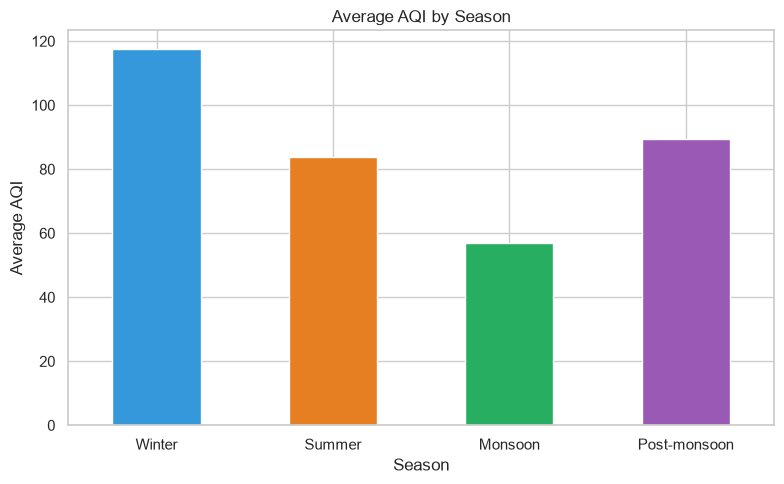

In [73]:
season_aqi = df.groupby("season")["us_aqi"].mean().reindex(season_order)

print(season_aqi.round(1))

plt.figure(figsize=(8, 5))
season_aqi.plot(kind="bar", color=["#3498db", "#e67e22", "#27ae60", "#9b59b6"])
plt.title("Average AQI by Season")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/key_charts/season_aqi.png")
plt.show()

**Summary:** Winter (Dec to Feb) is the most polluted season with an average AQI of 117.5, followed by post-monsoon (89.4) and summer (83.9). The monsoon is the cleanest at 56.8, which is 60.7 points lower than winter. Heavy rain likely washes particles out of the air in the monsoon.

### Q13. How much does AQI vary within each season?

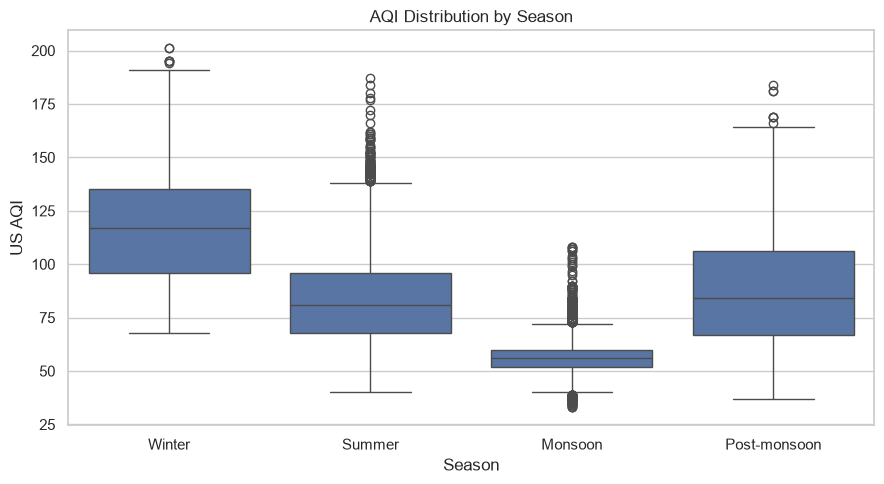

In [74]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="season", y="us_aqi", order=season_order)
plt.title("AQI Distribution by Season")
plt.xlabel("Season")
plt.ylabel("US AQI")
plt.tight_layout()
plt.savefig("../images/key_charts/season_aqi_boxplot.png")
plt.show()

**Summary:** Winter has the highest values overall (median 117, reaching 201). The monsoon is the most stable, with the middle half of readings between just 52 and 60. Winter and post-monsoon have the widest spread (a middle range of about 39 points each), so air quality in those seasons is less predictable.

## Part C: Trends and Bad Days

### Q14. Did air quality improve from Year 1 to Year 2?

Year 1 is 19 Nov 2024 to 18 Nov 2025 and Year 2 is 19 Nov 2025 to 19 Nov 2026. Both are 12 months long, so the comparison is fair.

        us_aqi  pm10  pm2_5  nitrogen_dioxide  ozone
period                                              
Year 1    81.3  28.0   23.9              13.8   64.5
Year 2    86.7  30.1   26.4              14.2   69.3

% change (Year 2 vs Year 1):
us_aqi               6.7
pm10                 7.5
pm2_5               10.6
nitrogen_dioxide     3.0
ozone                7.4
dtype: float64


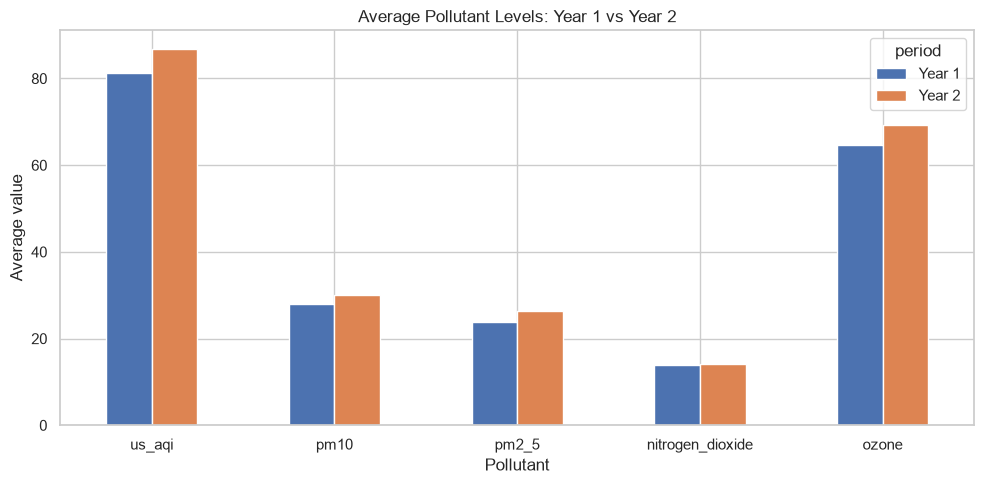

In [75]:
yearly = df.groupby("period")[["us_aqi", "pm10", "pm2_5", "nitrogen_dioxide", "ozone"]].mean()

print(yearly.round(1))
print()
print("% change (Year 2 vs Year 1):")
print(((yearly.loc["Year 2"] / yearly.loc["Year 1"] - 1) * 100).round(1))

yearly.T.plot(kind="bar", figsize=(10, 5))

plt.title("Average Pollutant Levels: Year 1 vs Year 2")
plt.xlabel("Pollutant")
plt.ylabel("Average value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/key_charts/yearly_pollutants.png")
plt.show()

**Summary:** Year 2 is slightly worse than Year 1. Average AQI rose from 81.3 to 86.7 (+6.7%), and PM2.5 rose the most, by 10.6% (from 23.9 to 26.4 µg/m³). Air quality in Kochi did not improve over the two years, although two years is too short to call this a long-term trend.

### Q15. What does daily AQI look like over the two years?

Highest daily AQI: 161.0
Date: 2025-12-23
Lowest daily AQI: 37.8
Date: 2025-08-29


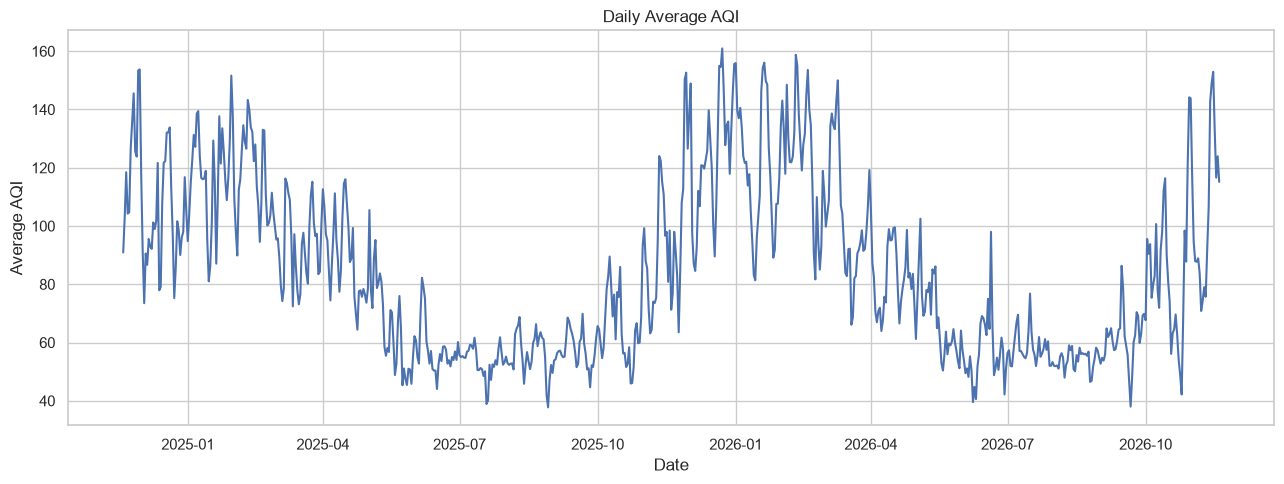

In [76]:
print("Highest daily AQI:", round(daily["us_aqi"].max(), 1))
print("Date:", daily["us_aqi"].idxmax())
print("Lowest daily AQI:", round(daily["us_aqi"].min(), 1))
print("Date:", daily["us_aqi"].idxmin())

plt.figure(figsize=(13, 5))
daily["us_aqi"].plot()
plt.title("Daily Average AQI")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.savefig("../images/key_charts/daily_aqi.png")
plt.show()

**Summary:** Daily AQI rises in winter (Dec to Feb) and drops in the monsoon (Jun to Sep). The highest daily average was 161.0 on 23 Dec 2025 and the lowest was 37.8 on 29 Aug 2025. The same seasonal swing appears across the two years.

### Q16. What is the long-term trend after smoothing?

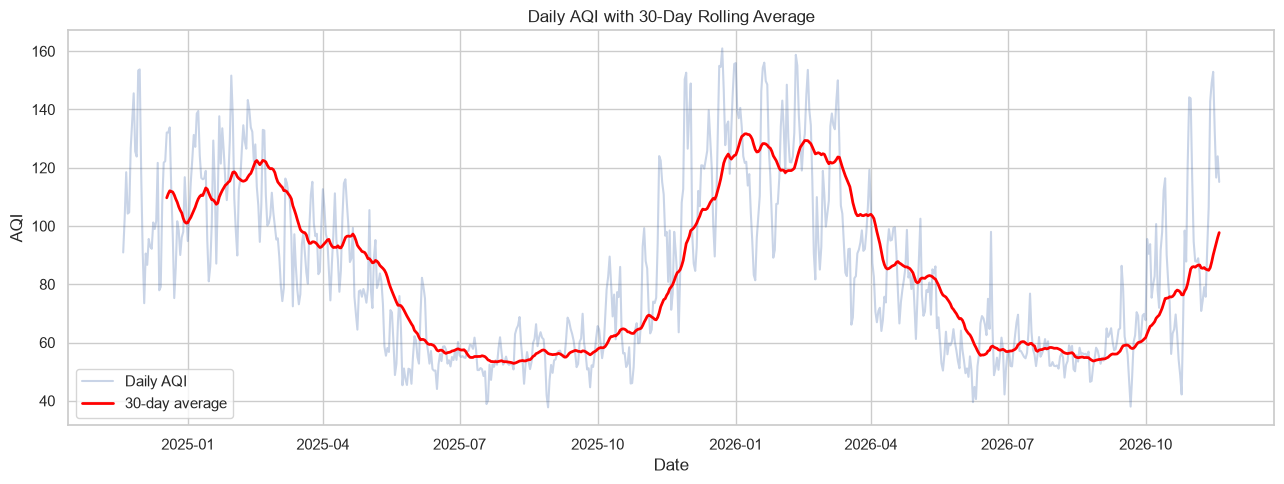

In [77]:
plt.figure(figsize=(13, 5))
daily["us_aqi"].plot(alpha=0.3, label="Daily AQI")
daily["us_aqi"].rolling(30).mean().plot(color="red", linewidth=2, label="30-day average")
plt.title("Daily AQI with 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.savefig("../images/key_charts/aqi_rolling_average.png")
plt.show()

**Summary:** The 30-day average shows a clear seasonal cycle: it peaks at about 131.7 around 8 Jan 2026 and falls to its lowest of about 52.8 around 6 Aug 2025. The seasons drive the pattern, and two years is too short to say whether there is a steady long-term rise or fall.

### Q17. Which 10 days were the worst?

date
2025-12-23    161.0
2026-02-10    158.8
2026-01-20    156.1
2026-01-01    155.9
2025-12-31    155.6
2026-02-11    155.0
2025-12-21    155.0
2025-12-22    154.6
2026-01-19    154.3
2024-11-30    153.8
Name: us_aqi, dtype: float64


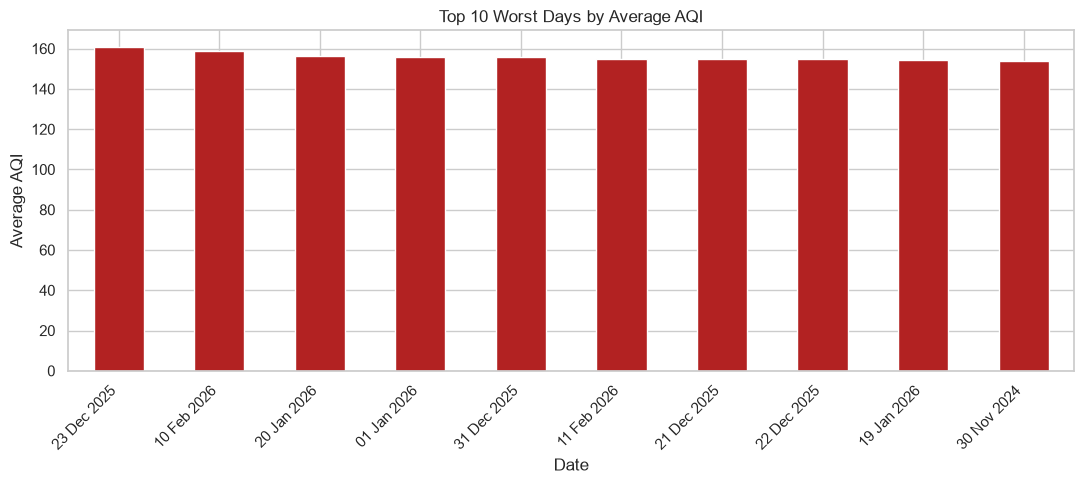

In [78]:
worst_days = daily["us_aqi"].sort_values(ascending=False).head(10)

print(worst_days.round(1))

worst_days.index = pd.to_datetime(worst_days.index).strftime("%d %b %Y")

plt.figure(figsize=(11, 5))
worst_days.plot(kind="bar", color="firebrick")
plt.title("Top 10 Worst Days by Average AQI")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../images/key_charts/worst_aqi_days.png")
plt.show()

**Summary:** Nine of the ten worst days fall in winter (21 Dec 2025 to 11 Feb 2026), and the tenth is 30 Nov 2024. The worst day was 23 Dec 2025 with an average AQI of 161.0, and all ten are between about 154 and 161. The worst days are clustered in the cold season, not isolated events.

### Q18. How many days exceed the PM2.5 limits?

The WHO 24-hour guideline is 15 µg/m³ and the Indian CPCB 24-hour standard is 60 µg/m³.

Days above WHO limit: 488 of 731 (66.8%)
Days above CPCB limit: 7 of 731 (1.0%)


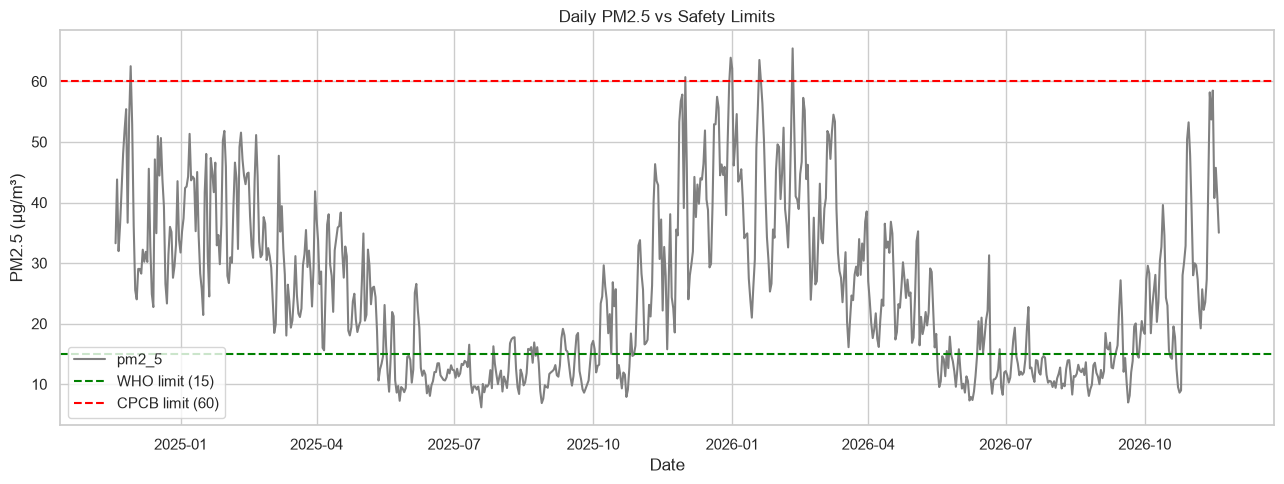

In [79]:
total_days = len(daily)
above_who = (daily["pm2_5"] > 15).sum()
above_cpcb = (daily["pm2_5"] > 60).sum()

print("Days above WHO limit:", above_who, "of", total_days, f"({above_who / total_days * 100:.1f}%)")
print("Days above CPCB limit:", above_cpcb, "of", total_days, f"({above_cpcb / total_days * 100:.1f}%)")

plt.figure(figsize=(13, 5))
daily["pm2_5"].plot(color="gray")
plt.axhline(15, color="green", linestyle="--", label="WHO limit (15)")
plt.axhline(60, color="red", linestyle="--", label="CPCB limit (60)")
plt.title("Daily PM2.5 vs Safety Limits")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig("../images/key_charts/daily_pm2_5_limits.png")
plt.show()

**Summary:** 488 of 731 days (66.8%) are above the WHO 24-hour PM2.5 guideline of 15 µg/m³, but only 7 days (1.0%) exceed the Indian CPCB limit of 60 µg/m³. The highest daily PM2.5 was 65.4 µg/m³ on 10 Feb 2026. Air quality meets Indian standards on most days but regularly exceeds WHO guidance.

## Part D: Relationships Between Pollutants

### Q19. Which pollutants are most correlated?

pm10                0.76
pm2_5               0.81
nitrogen_dioxide    0.26
sulphur_dioxide     0.60
ozone               0.48
carbon_monoxide     0.60
us_aqi              1.00
Name: us_aqi, dtype: float64


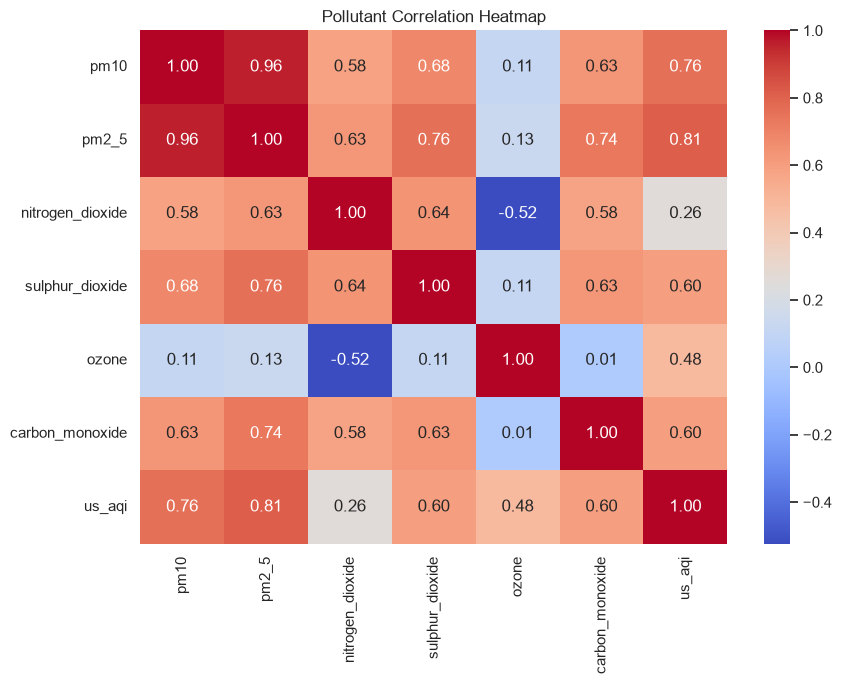

In [80]:
corr = df[pollutants + ["us_aqi"]].corr()

print(corr["us_aqi"].round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Pollutant Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/key_charts/correlation_heatmap.png")
plt.show()

**Summary:** PM2.5 has the strongest relationship with AQI (r = 0.81), followed by PM10 (0.76). SO₂ and CO are both at 0.60, ozone is 0.48, and NO₂ is the weakest at 0.26. Particulate matter, especially PM2.5, is the main driver of Kochi's AQI.

### Q20. How do PM2.5 and PM10 relate?

Correlation: 0.96


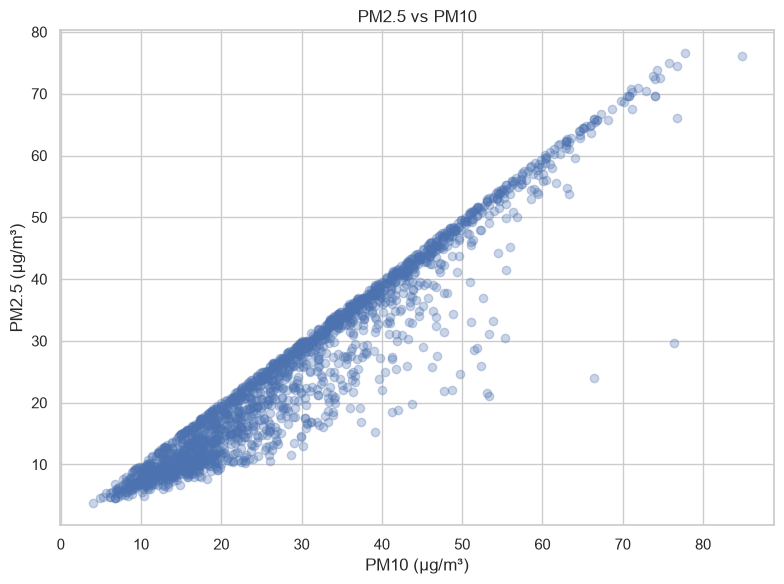

In [81]:
sample = df.sample(2000, random_state=42)

print("Correlation:", round(df["pm2_5"].corr(df["pm10"]), 2))

plt.figure(figsize=(8, 6))
plt.scatter(sample["pm10"], sample["pm2_5"], alpha=0.3)
plt.title("PM2.5 vs PM10")
plt.xlabel("PM10 (µg/m³)")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()

plt.savefig("../images/key_charts/pm2_5_vs_pm10.png")
plt.show()

**Summary:** PM2.5 and PM10 are almost perfectly linked (r = 0.96), and the points sit tightly along an upward line. When coarse particles rise, fine particles rise with them, which suggests a shared source or shared weather conditions.

### Q21. Which season has more fine particles?

A high PM2.5/PM10 ratio means most particles are fine, which is typical of combustion and smoke. A lower ratio means a larger share of coarser particles such as dust.

season
Winter          0.97
Summer          0.83
Monsoon         0.68
Post-monsoon    0.92
Name: pm_ratio, dtype: float64


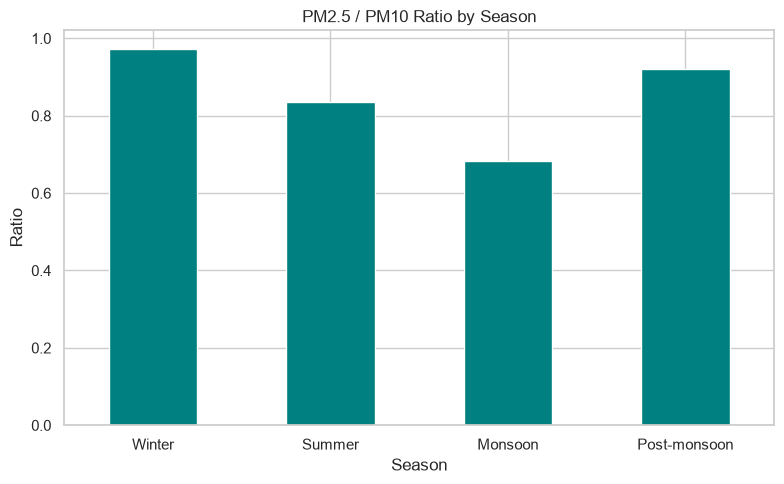

In [82]:
df["pm_ratio"] = df["pm2_5"] / df["pm10"]

ratio_by_season = df.groupby("season")["pm_ratio"].mean().reindex(season_order)

print(ratio_by_season.round(2))

plt.figure(figsize=(8, 5))
ratio_by_season.plot(kind="bar", color="teal")
plt.title("PM2.5 / PM10 Ratio by Season")
plt.xlabel("Season")
plt.ylabel("Ratio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/key_charts/pm_ratio_by_season.png")
plt.show()

**Summary:** The ratio is highest in winter (0.97) and post-monsoon (0.92) and lowest in the monsoon (0.68). In winter almost all particles are fine particles, which points to combustion or trapped smoke. In the monsoon a larger share may be coarser particles such as dust.

### Q22. How do NO₂ and ozone relate?

Correlation: -0.52


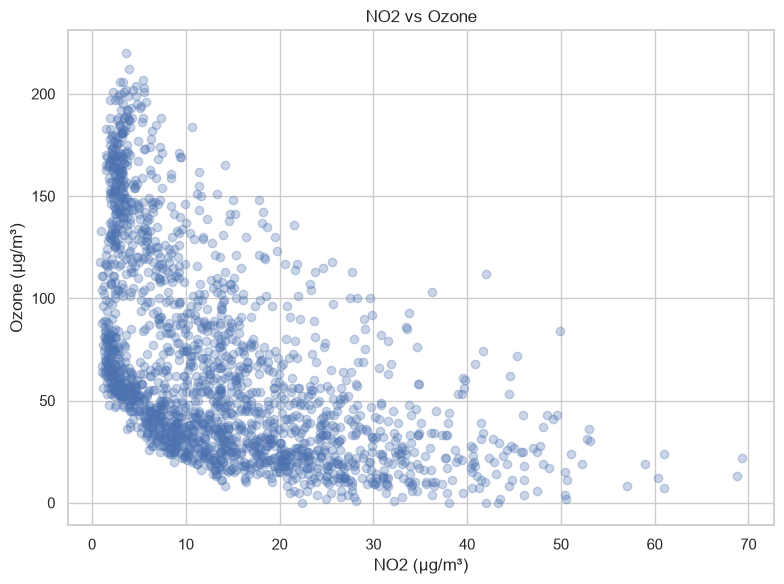

In [83]:
sample = df.sample(2000, random_state=42)

print("Correlation:", round(df["nitrogen_dioxide"].corr(df["ozone"]), 2))

plt.figure(figsize=(8, 6))
plt.scatter(sample["nitrogen_dioxide"], sample["ozone"], alpha=0.3)
plt.title("NO2 vs Ozone")
plt.xlabel("NO2 (µg/m³)")
plt.ylabel("Ozone (µg/m³)")
plt.tight_layout()

plt.savefig("../images/key_charts/no2_vs_ozone.png")
plt.show()

**Summary:** NO₂ and ozone have a negative correlation (r = -0.52): when NO₂ is high, ozone tends to be low. This matches the hourly patterns in Q7 and Q8, where ozone peaks at 13:00 while NO₂ is at its lowest.

## Part E: Deeper Insights

### Q23. Which month and hour combination is worst?

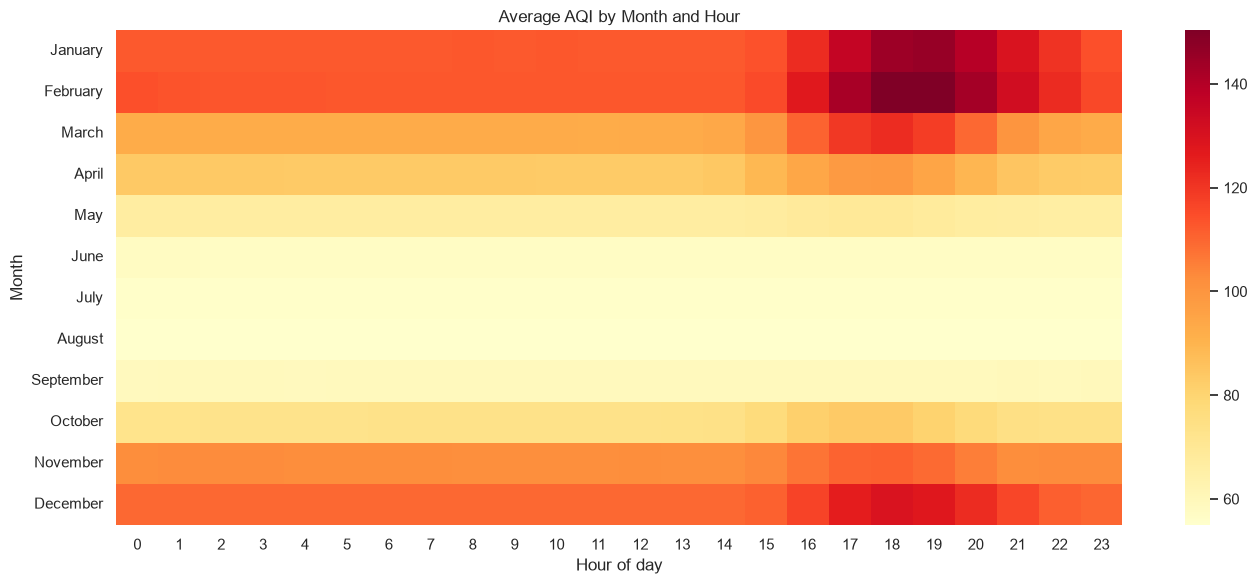

In [84]:
pivot = df.pivot_table(values="us_aqi", index="month", columns="hour", aggfunc="mean")
pivot = pivot.reindex(month_order)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot, cmap="YlOrRd")

plt.title("Average AQI by Month and Hour")
plt.xlabel("Hour of day")
plt.ylabel("Month")

plt.tight_layout()
plt.savefig("../images/key_charts/month_hour_aqi_heatmap.png")
plt.show()

**Summary:** The worst combination is February at 18:00 (AQI 150.3) and the best is August at 14:00 (54.9). In the winter months the evening hours (about 17:00 to 20:00) form the darkest zone, while the monsoon months stay light all day. The season matters more than the hour: February and August differ by about 66 points on average, whereas the hours within February differ by about 37 points (113 to 150).

### Q24. What mix of AQI categories does each season have?

aqi_category  Good  Moderate  Unhealthy for Sensitive  Unhealthy  \
season                                                             
Winter         0.0      30.5                     57.4       12.1   
Summer         3.3      77.5                     18.4        0.8   
Monsoon       12.3      87.5                      0.2        0.0   
Post-monsoon   3.1      68.2                     23.8        4.9   

aqi_category  Very Unhealthy  
season                        
Winter                   0.0  
Summer                   0.0  
Monsoon                  0.0  
Post-monsoon             0.0  


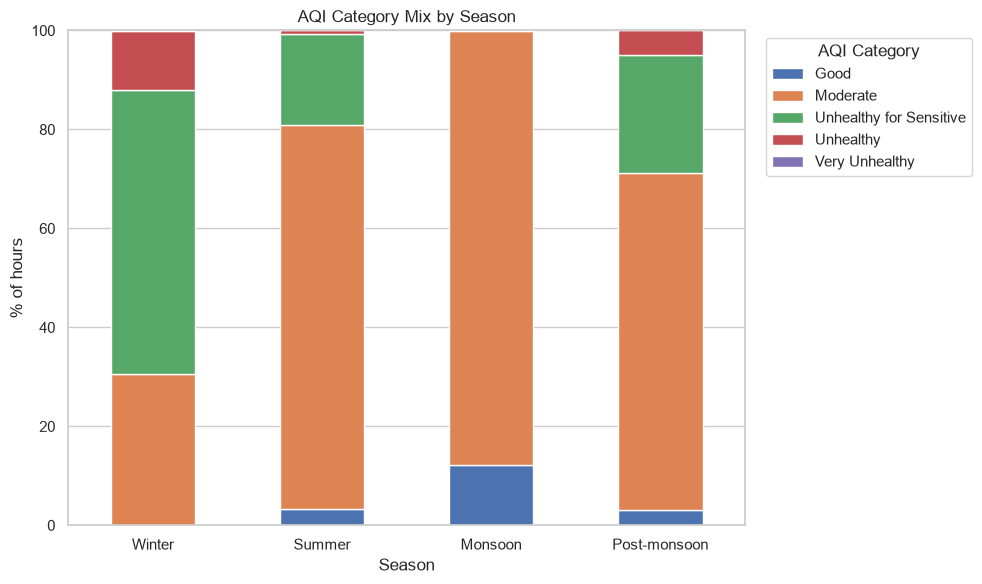

In [85]:
season_category = pd.crosstab(df["season"], df["aqi_category"], normalize="index") * 100
season_category = season_category.reindex(index=season_order, columns=category_order, fill_value=0)

print(season_category.round(1))

season_category.plot(kind="bar", stacked=True, figsize=(10, 6))

plt.title("AQI Category Mix by Season")
plt.xlabel("Season")
plt.ylabel("% of hours")
plt.xticks(rotation=0)
plt.legend(title="AQI Category", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig("../images/key_charts/season_aqi_category_mix.png")
plt.show()

**Summary:** Winter has no Good hours, 57.4% of its hours are Unhealthy for Sensitive Groups and 12.1% are Unhealthy (69.5% combined). The monsoon is the opposite: 87.5% Moderate, 12.3% Good and almost nothing worse. Sensitive people should take the most care in winter and post-monsoon (23.8% Unhealthy for Sensitive Groups).

### Q25. What is the best time of day to go out?

For each hour, we calculate the percentage of hours with an AQI of 100 or below (acceptable air).

Best hour : 1 (77.8% acceptable)
Worst hour: 18 (59.5% acceptable)


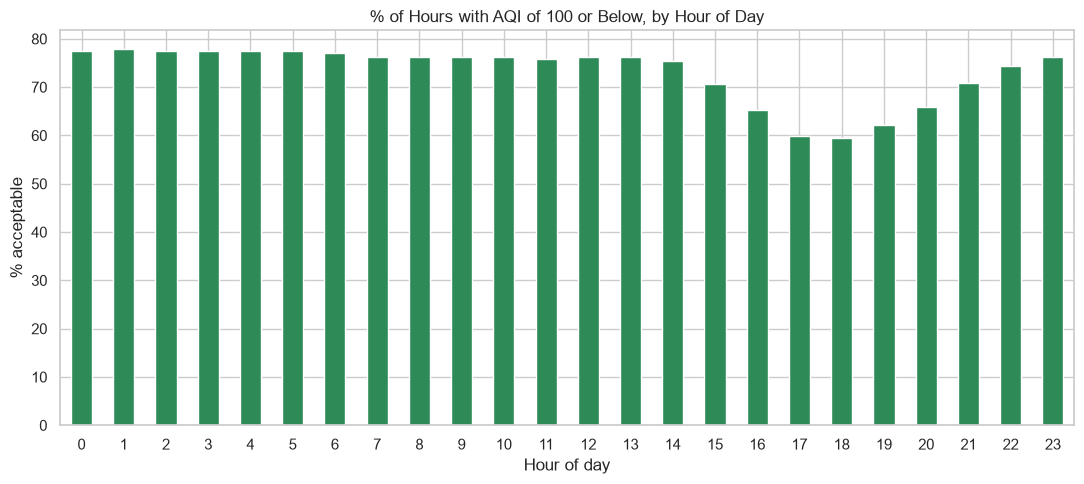

In [86]:
df["acceptable"] = df["us_aqi"] <= 100
acceptable_by_hour = df.groupby("hour")["acceptable"].mean() * 100

print("Best hour :", acceptable_by_hour.idxmax(), f"({acceptable_by_hour.max():.1f}% acceptable)")
print("Worst hour:", acceptable_by_hour.idxmin(), f"({acceptable_by_hour.min():.1f}% acceptable)")

plt.figure(figsize=(11, 5))
acceptable_by_hour.plot(kind="bar", color="seagreen")

plt.title("% of Hours with AQI of 100 or Below, by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("% acceptable")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("../images/key_charts/acceptable_aqi_by_hour.png")
plt.show()

**Summary:** The best hour is 01:00, with 77.8% of hours at AQI 100 or below, and the worst is 18:00 at 59.5%. From 00:00 to 14:00 the share stays at about 75% to 78%, then drops through the afternoon to its lowest point in the early evening. For outdoor activity, the morning and early afternoon are the best choice, and 16:00 to 20:00 should be avoided, especially in winter.

# Saving the Cleaned Data

The cleaned hourly data and a daily summary are saved in `data/processed`.

In [87]:
df_clean = df.drop(columns=["pm_ratio", "acceptable"], errors="ignore")

df_clean.to_csv("../data/processed/kochi_air_quality_clean.csv", index=False)

print("Hourly file saved")
print("Shape:", df_clean.shape)

Hourly file saved
Shape: (17544, 17)


In [88]:
daily_summary = df.groupby("date").agg(
    aqi_mean=("us_aqi", "mean"),
    aqi_max=("us_aqi", "max"),
    pm2_5=("pm2_5", "mean"),
    pm10=("pm10", "mean"),
    no2=("nitrogen_dioxide", "mean"),
    so2=("sulphur_dioxide", "mean"),
    ozone=("ozone", "mean"),
    co=("carbon_monoxide", "mean"),
    season=("season", "first"),
    month=("month", "first"),
    weekday=("weekday", "first")
).reset_index()

daily_summary["aqi_category"] = daily_summary["aqi_mean"].apply(get_category)

daily_summary.to_csv("../data/processed/kochi_air_quality_daily.csv", index=False)

print("Daily file saved")
print("Shape:", daily_summary.shape)

Daily file saved
Shape: (731, 13)


## Summary of Exploratory Data Analysis

The Exploratory Data Analysis (EDA) was conducted to understand air quality patterns in Kochi using two years of hourly air pollution data (19 Nov 2024 to 19 Nov 2026, 17,544 records, no missing values or duplicates).

1. The average AQI is 84.0. About 67.7% of hours are Moderate, 22.8% are Unhealthy for Sensitive Groups, 4.0% are Unhealthy, and only 5.5% are Good.
2. PM2.5 is the main driver of AQI (correlation 0.81), and PM2.5 and PM10 move almost together (0.96).
3. The evening is the most polluted time of day: AQI peaks at 18:00 (94.4).
4. Winter is the most polluted season (AQI 117.5) and the monsoon the cleanest (56.8). February is the worst month (120.6) and August the best (55.0).
5. Weekdays (84.2) and weekends (83.6) are almost the same.
6. Year 2 is worse than Year 1: AQI is up 6.7% and PM2.5 is up 10.6%.
7. 66.8% of days exceed the WHO PM2.5 guideline, but only 1.0% exceed the Indian CPCB limit.
8. Nine of the ten worst days fall in winter, and the worst was 23 Dec 2025 (AQI 161.0).

## Conclusion

The analysis shows that air quality in Kochi follows a strong seasonal pattern. The air is cleanest during the monsoon (average AQI 56.8) and worst in winter (117.5), when more than two thirds of hours are Unhealthy for Sensitive Groups or worse. Within a day, pollution is highest in the evening, with a peak at 18:00.

PM2.5 is the pollutant most closely linked with the AQI, and it exceeds the WHO daily guideline on about two thirds of days, although it stays within the Indian CPCB standard on almost every day. The second year of data was slightly worse than the first, but two years is too short to call this a long-term trend.

## Key Findings

- The average AQI is 84.0, and only 5.5% of hours have Good air quality.
- Winter (Dec to Feb) is the worst season at 117.5 AQI, against 56.8 in the monsoon. February is the worst month (120.6).
- The most polluted hour is 18:00 (AQI 94.4), and 16:00 to 20:00 has the lowest share of acceptable air (about 60% to 66% of hours at AQI 100 or below).
- Weekday and weekend air quality are almost identical (84.2 vs 83.6).
- PM2.5 has the strongest link with AQI (r = 0.81), and PM2.5 and PM10 are almost perfectly correlated (r = 0.96).
- NO₂ and ozone move in opposite directions (r = -0.52): NO₂ peaks at 22:00 while ozone peaks at 13:00.
- 66.8% of days exceed the WHO PM2.5 guideline (15 µg/m³), but only 1.0% exceed the CPCB limit (60 µg/m³).
- Year 2 had 6.7% higher AQI and 10.6% higher PM2.5 than Year 1.

## Business Insights

- **Residents and outdoor workers:** the best time for outdoor exercise is the morning and early afternoon. Evening hours (16:00 to 20:00) have the least acceptable air and should be avoided, especially in winter.
- **Sensitive groups:** winter has 69.5% of hours at Unhealthy for Sensitive Groups or worse, so children, older people and people with breathing problems need the most care from December to February.
- **City planners and authorities:** air quality warnings and monitoring should be prioritised for the winter months and for evening hours, when pollution peaks.
- **Policy:** PM2.5 is the main driver of AQI, so pollution control efforts should focus on fine particles. Kochi mostly meets the Indian standard but exceeds WHO guidance on about two thirds of days.
- **Public awareness:** the seasonal pattern is clear enough to support seasonal health advisories and awareness campaigns.

## Future Scope

- Integrate real-time air quality data for continuous monitoring.
- Merge weather data (rain, wind, temperature) to explain the seasonal patterns instead of assuming them.
- Compare air quality across multiple cities in Kerala.
- Validate the model-based values against ground sensor data.
- Develop machine learning models to predict future AQI levels.
- Build an interactive dashboard using Power BI to visualize air quality trends.

## Final Conclusion

This project used Python (Pandas, NumPy, Matplotlib and Seaborn) to explore two years of hourly air quality data for Kochi. The dataset was checked and cleaned, new time-based features were created, and 25 questions were answered with charts and written summaries.

The main result is that Kochi's air quality is strongly seasonal, with the worst air in winter and the cleanest in the monsoon, and that PM2.5 is the key pollutant to watch. The results provide a foundation for further analysis, such as adding weather data and building a forecasting model.